# SECOM - Dataset Exploration

**Semiconductor Failure Prediction - Week 1**

Dataset: [UCI SECOM](https://archive.ics.uci.edu/dataset/179/secom) (McCann & Johnston, 2008).

The goal here is to understand the dataset and identify data quality problems before preprocessing and training models.

### Load the data

`load_secom()` (in `src/secom.py`) downloads the UCI files into `data/` the first time.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # run from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.secom import load_secom

X, y = load_secom()
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print(y.value_counts())

display(X.head())

Features shape: (1567, 590)
Target shape: (1567,)
fail
0    1463
1     104
Name: count, dtype: int64


,sensor_0,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,...,sensor_580,sensor_581,sensor_582,sensor_583,sensor_584,sensor_585,sensor_586,sensor_587,sensor_588,sensor_589
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,...,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,...,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,...,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,...,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,...,NaN,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432


UCI describes 1,567 production entities, with many anonymized process measurements. The exact feature count is checked from the downloaded dataframe rather than assumed.

### General information

In [2]:
print("Rows:", len(X))
print("Features:", X.shape[1])
print("Numeric features:", X.select_dtypes(include="number").shape[1])
print("Non-numeric features:", X.select_dtypes(exclude="number").shape[1])
print("Total missing values:", int(X.isna().sum().sum()))
print("Duplicate feature rows:", int(X.duplicated().sum()))
print("Feature names (first 15):", X.columns[:15].tolist())

Rows: 1567
Features: 590
Numeric features: 590
Non-numeric features: 0
Total missing values: 41951
Duplicate feature rows: 0
Feature names (first 15): ['sensor_0', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14']


### Target distribution

In the UCI file, `-1` means Pass and `1` means Fail. `load_secom` encodes them as `0` (Pass) and `1` (Fail). The positive class is Fail.

,Count,Percentage (%)
Pass (0),1463,93.36
Fail (1),104,6.64


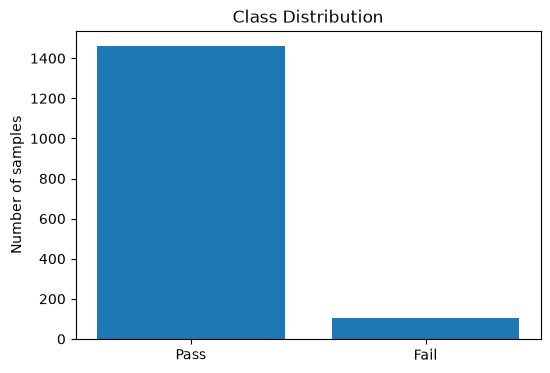

Failure rate: 6.64 %


In [3]:
# Class distribution
class_counts = y.value_counts().sort_index()
class_percent = y.value_counts(normalize=True).sort_index() * 100

class_table = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_percent.round(2)
})

class_table.index = ["Pass (0)", "Fail (1)"]
display(class_table)

plt.figure(figsize=(6, 4))
plt.bar(["Pass", "Fail"], class_counts.values)
plt.ylabel("Number of samples")
plt.title("Class Distribution")
plt.show()

print("Failure rate:", round((y == 1).mean() * 100, 2), "%")

The classes are highly imbalanced. Accuracy alone will not be enough to evaluate failure detection.

### Missing values

Columns with at least one missing value: 538
Columns with > 50% missing: 28
Columns with > 80% missing: 8


Overall missing percentage: 4.54


,Missing values,Missing (%)
sensor_292,1429,91.19
sensor_293,1429,91.19
sensor_158,1429,91.19
sensor_157,1429,91.19
sensor_492,1341,85.58
sensor_85,1341,85.58
sensor_358,1341,85.58
sensor_220,1341,85.58
sensor_244,1018,64.96
sensor_517,1018,64.96


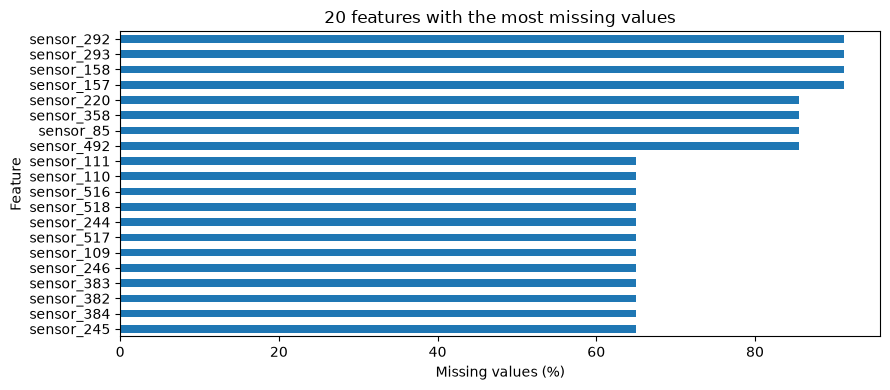

In [4]:
missing_count = X.isna().sum()
missing_pct = X.isna().mean() * 100
missing_df = pd.DataFrame({"Missing values": missing_count,
                           "Missing (%)": missing_pct}).sort_values("Missing (%)", ascending=False)

print("Columns with at least one missing value:", int((missing_count > 0).sum()))
print("Columns with > 50% missing:", int((missing_pct > 50).sum()))
print("Columns with > 80% missing:", int((missing_pct > 80).sum()))
print("Overall missing percentage:", round(X.isna().to_numpy().mean()*100, 2))
display(missing_df.head(15).round(2))

fig, ax = plt.subplots(figsize=(9, 4))
missing_df.head(20).sort_values("Missing (%)")["Missing (%)"].plot.barh(ax=ax)
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("Feature")
ax.set_title("20 features with the most missing values")
plt.tight_layout()
plt.show()

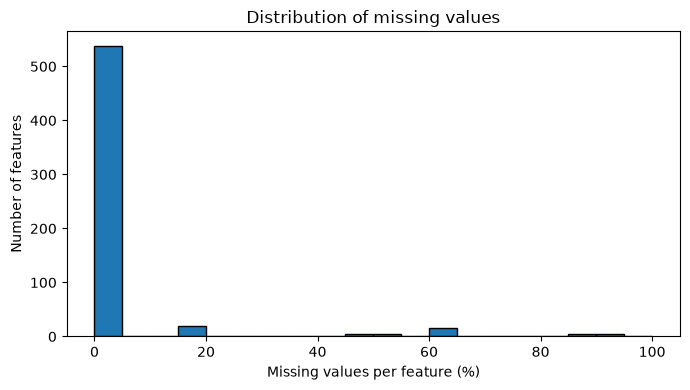

Rows with at least one missing value: 1567
Maximum missing percentage in one row: 25.76


In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(missing_pct, bins=np.arange(0, 105, 5), edgecolor="black")
ax.set_xlabel("Missing values per feature (%)")
ax.set_ylabel("Number of features")
ax.set_title("Distribution of missing values")
plt.tight_layout()
plt.show()

row_missing_pct = X.isna().mean(axis=1) * 100
print("Rows with at least one missing value:", int((row_missing_pct > 0).sum()))
print("Maximum missing percentage in one row:", round(row_missing_pct.max(), 2))

### Constant and redundant features

Constant features cannot help distinguish Pass from Fail. We also look for very highly correlated features, which may contain nearly the same information. We only identify these problems here; we do not remove columns yet.

In [6]:
unique_values = X.nunique(dropna=True)
constant_cols = unique_values[unique_values <= 1].index.tolist()
near_constant_cols = []
for col in X.columns:
    values = X[col].dropna()
    if len(values) > 0 and values.nunique() > 1:
        if values.value_counts(normalize=True).iloc[0] >= 0.99:
            near_constant_cols.append(col)

print("Constant / all-NaN features:", len(constant_cols))
print("Near-constant features (>=99% identical non-missing values):", len(near_constant_cols))
print("First constant features:", constant_cols[:20])
print("First near-constant features:", near_constant_cols[:20])

Constant / all-NaN features: 116
Near-constant features (>=99% identical non-missing values): 6
First constant features: ['sensor_5', 'sensor_13', 'sensor_42', 'sensor_49', 'sensor_52', 'sensor_69', 'sensor_97', 'sensor_141', 'sensor_149', 'sensor_178', 'sensor_179', 'sensor_186', 'sensor_189', 'sensor_190', 'sensor_191', 'sensor_192', 'sensor_193', 'sensor_194', 'sensor_226', 'sensor_229']
First near-constant features: ['sensor_74', 'sensor_206', 'sensor_209', 'sensor_342', 'sensor_347', 'sensor_478']


In [7]:
# Pearson correlation on numeric, non-constant features only.
numeric = X.select_dtypes(include="number").drop(columns=constant_cols, errors="ignore")
corr = numeric.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
correlated_pairs = upper.stack().sort_values(ascending=False)
strong_pairs = correlated_pairs[correlated_pairs >= 0.98]

print("Feature pairs with |Pearson correlation| >= 0.98:", len(strong_pairs))
display(strong_pairs.head(15).rename("Absolute correlation").to_frame())

# Note: correlation uses pairwise available values, so very sparse columns need caution.

Feature pairs with |Pearson correlation| >= 0.98: 201


Absolute correlation
sensor_74  sensor_342                   1.0
           sensor_347                   1.0
           sensor_209                   1.0
sensor_85  sensor_542                   1.0
sensor_74  sensor_478                   1.0
sensor_220 sensor_543                   1.0
sensor_209 sensor_342                   1.0
           sensor_347                   1.0
           sensor_478                   1.0
sensor_492 sensor_545                   1.0
sensor_206 sensor_209                   1.0
sensor_342 sensor_347                   1.0
sensor_358 sensor_544                   1.0
sensor_578 sensor_586                   1.0
sensor_580 sensor_588                   1.0

### A quick look at a few feature distributions

These are anonymized measurements, so it is difficult to relate them to physical sensors. The following plots help identify differences in scale and unusual values, without deciding yet whether they are errors.

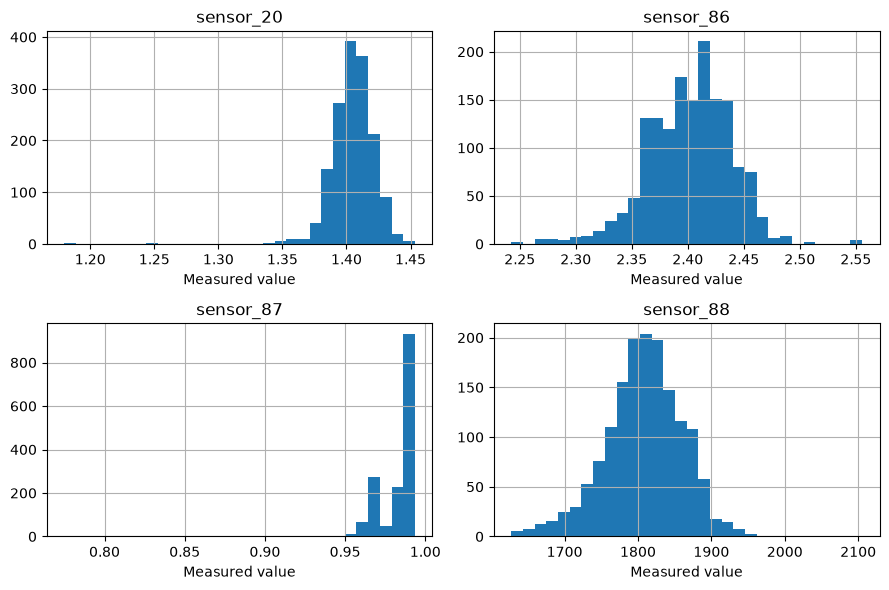

In [8]:
# Take four non-constant numeric features with relatively few missing values.
valid_cols = [c for c in numeric.columns if X[c].notna().sum() > 0]
example_cols = sorted(valid_cols, key=lambda c: missing_pct[c])[:4]
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for col, ax in zip(example_cols, axes.ravel()):
    X[col].dropna().hist(bins=30, ax=ax)
    ax.set_title(str(col))
    ax.set_xlabel("Measured value")
plt.tight_layout()
plt.show()

### Summary for the group

The numbers below can be copied into the Week 1 report. We have not trained a model or decided which features to remove.

In [9]:
print(f"Dataset: {X.shape[0]} samples, {X.shape[1]} features")
print(f"Pass: {class_counts.loc[0]} ({class_percent.loc[0]:.1f}%)")
print(f"Fail: {class_counts.loc[1]} ({class_percent.loc[1]:.1f}%)")
print(f"Overall missing data: {X.isna().to_numpy().mean()*100:.1f}%")
print(f"Features with missing data: {(missing_count > 0).sum()}")

Dataset: 1567 samples, 590 features
Pass: 1463 (93.4%)
Fail: 104 (6.6%)
Overall missing data: 4.5%
Features with missing data: 538


**Short discussion**

The dataset is highly imbalanced because failures are rare. We also need to handle missing measurements, check constant features and consider correlations between sensors. Since the sensor names are anonymized, identifying a statistically useful feature does not necessarily explain its physical meaning.

For Week 2, missing-value imputation, scaling, feature selection and possible class-imbalance methods should be tested **inside the training folds**. The test set should not be used to decide preprocessing choices or model parameters.

**Source:** McCann, M. & Johnston, A. (2008), *SECOM*, UCI Machine Learning Repository. https://doi.org/10.24432/C54305